# MultiAmr2Cube — Variant Comparison

Runs all variants, checks correctness, and plots timing.

**Run from the `multiamr2cube_optim/` directory** (or set `BASE_DIR` below).

Variants:
- `ref`        — reference Python loop over coarse cells (matches notebook)
- `numpy`      — coarse cells batched per level with numpy broadcasting
- `numba`      — coarse loop compiled with `@njit(parallel=True)`
- `numba_full` — fully-numba single-pass kernel: index compute + fine scatter + coarse fill, no temporary arrays

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import time
from configparser import ConfigParser

# --- point to the right directories ---
BASE_DIR = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'claude' else os.getcwd()
CLAUDE_DIR = os.path.join(BASE_DIR, 'claude')
sys.path.insert(0, BASE_DIR)
sys.path.insert(0, CLAUDE_DIR)

import pyablo
import multiamr2cube_ref        as m_ref
import multiamr2cube_numpy      as m_numpy
import multiamr2cube_numba      as m_numba
import multiamr2cube_numba_full as m_numba_full

print('BASE_DIR:', BASE_DIR)

BASE_DIR: /Users/pedro/work/simus/dyablo/dyablo/multiamr2cube_optim


## 1 — Load snapshot data (once)

In [2]:
PATH       = BASE_DIR + '/'
SNAPNAME   = 'star'
CONFIGNAME = 'restart_star_279982.ini'
T          = 70000
FIELD      = 'rho'

config = ConfigParser(inline_comment_prefixes=('#', ';'))
config.read(PATH + CONFIGNAME)

reader = pyablo.XdmfReader()
snap = reader.readSnapshot(PATH + SNAPNAME + '_iter{:07d}.xmf'.format(T))

cc, lcell, Lbox = m_ref.extract_snapshot_data(snap, config)
values = np.array(snap.readAllFloat(FIELD), dtype=np.float64)

print(f'{len(values):,} cells | lmin={lcell.min()} lmax={lcell.max()} | Lbox={Lbox}')

27,825,344 cells | lmin=8 lmax=10 | Lbox=[1.84219576e+23 1.84219576e+23 1.84219576e+23]


## 2 — Warm up numba JIT

In [3]:
print('Compiling numba kernels...')
t0 = time.perf_counter()
m_numba.warmup(cc, lcell, values, Lbox)
m_numba_full.warmup(cc, lcell, values, Lbox)
print(f'  done in {time.perf_counter()-t0:.1f}s')

Compiling numba kernels...
  done in 0.4s


## 3 — Benchmark

In [ ]:
LCUBES    = [8, 9,10]   # add 10 if you have ~8 GB RAM to spare
N_REPEATS = 3

VARIANTS = {
    'ref':        m_ref.multiamr2cube,
    'numpy':      m_numpy.multiamr2cube,
    'numba':      m_numba.multiamr2cube,
    'numba_full': m_numba_full.multiamr2cube,
}

results = {}   # (name, lcube) -> {'times': [...], 'result': array}

for lcube in LCUBES:
    print(f'\n=== lcube={lcube}  ({2**lcube}^3 grid) ===')
    ref_arr = None
    for name, fn in VARIANTS.items():
        # warm-up run (not timed)
        _ = fn(cc, lcell, values, Lbox, lcube)
        times = []
        for _ in range(N_REPEATS):
            t0 = time.perf_counter()
            arr = fn(cc, lcell, values, Lbox, lcube)
            times.append(time.perf_counter() - t0)
        results[(name, lcube)] = {'times': times, 'result': arr}
        t_med = np.median(times)
        if ref_arr is None:
            ref_arr = arr
            correct = 'REF'
        else:
            rel = np.max(np.abs(arr - ref_arr)) / (np.max(np.abs(ref_arr)) + 1e-300)
            correct = f'OK (rel={rel:.1e})' if rel < 1e-10 else f'FAIL rel={rel:.2e}'
        print(f'  {name:<12}  median={t_med:.3f}s   {correct}')


=== lcube=8  (256^3 grid) ===
  ref           median=0.588s   REF
  numpy         median=0.580s   OK (rel=0.0e+00)
  numba         median=0.602s   OK (rel=0.0e+00)
  numba_full    median=0.052s   OK (rel=0.0e+00)

=== lcube=9  (512^3 grid) ===
  ref           median=9.227s   REF
  numpy         median=0.964s   OK (rel=0.0e+00)
  numba         median=0.701s   OK (rel=0.0e+00)
  numba_full    median=0.203s   OK (rel=0.0e+00)

=== lcube=10  (1024^3 grid) ===
  ref           median=15.939s   REF
  numpy         median=11.115s   OK (rel=0.0e+00)
  numba         median=1.975s   OK (rel=0.0e+00)
  numba_full    median=3.311s   OK (rel=0.0e+00)

=== lcube=10  (1024^3 grid) ===


## 4 — Timing plot

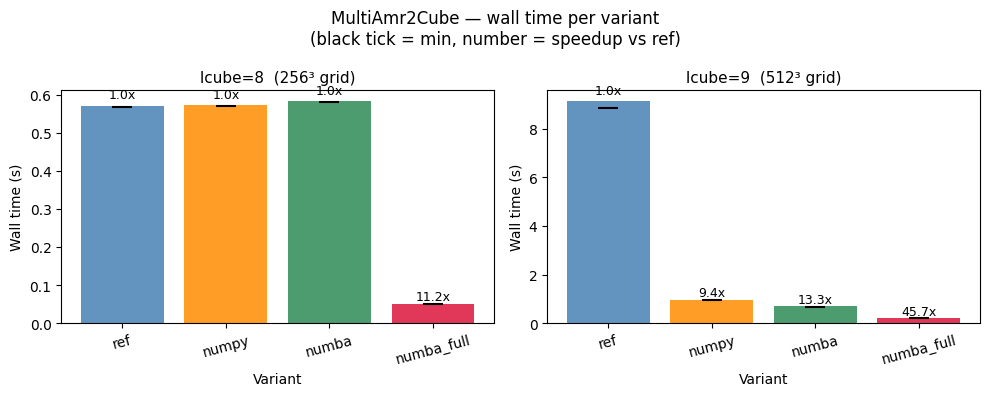

Saved timing.png


In [5]:
fig, axes = plt.subplots(1, len(LCUBES), figsize=(5 * len(LCUBES), 4), sharey=False)
if len(LCUBES) == 1:
    axes = [axes]

colors = {'ref': 'steelblue', 'numpy': 'darkorange', 'numba': 'seagreen', 'numba_full': 'crimson'}

for ax, lcube in zip(axes, LCUBES):
    names = list(VARIANTS.keys())
    medians = [np.median(results[(n, lcube)]['times']) for n in names]
    mins    = [np.min(results[(n, lcube)]['times'])    for n in names]
    bars = ax.bar(names, medians, color=[colors[n] for n in names], alpha=0.85)
    ax.scatter(names, mins, marker='_', s=200, color='black', zorder=5, label='min')
    ax.set_title(f'lcube={lcube}  ({2**lcube}³ grid)', fontsize=11)
    ax.set_ylabel('Wall time (s)')
    ax.set_xlabel('Variant')
    ax.tick_params(axis='x', rotation=15)
    ref_med = np.median(results[('ref', lcube)]['times'])
    for bar, med in zip(bars, medians):
        speedup = ref_med / med
        ax.text(bar.get_x() + bar.get_width()/2, med * 1.02,
                f'{speedup:.1f}x', ha='center', va='bottom', fontsize=9)

plt.suptitle('MultiAmr2Cube — wall time per variant\n(black tick = min, number = speedup vs ref)',
             fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(CLAUDE_DIR, 'timing.png'), dpi=150)
plt.show()
print('Saved timing.png')

## 5 — Correctness: visual slice comparison

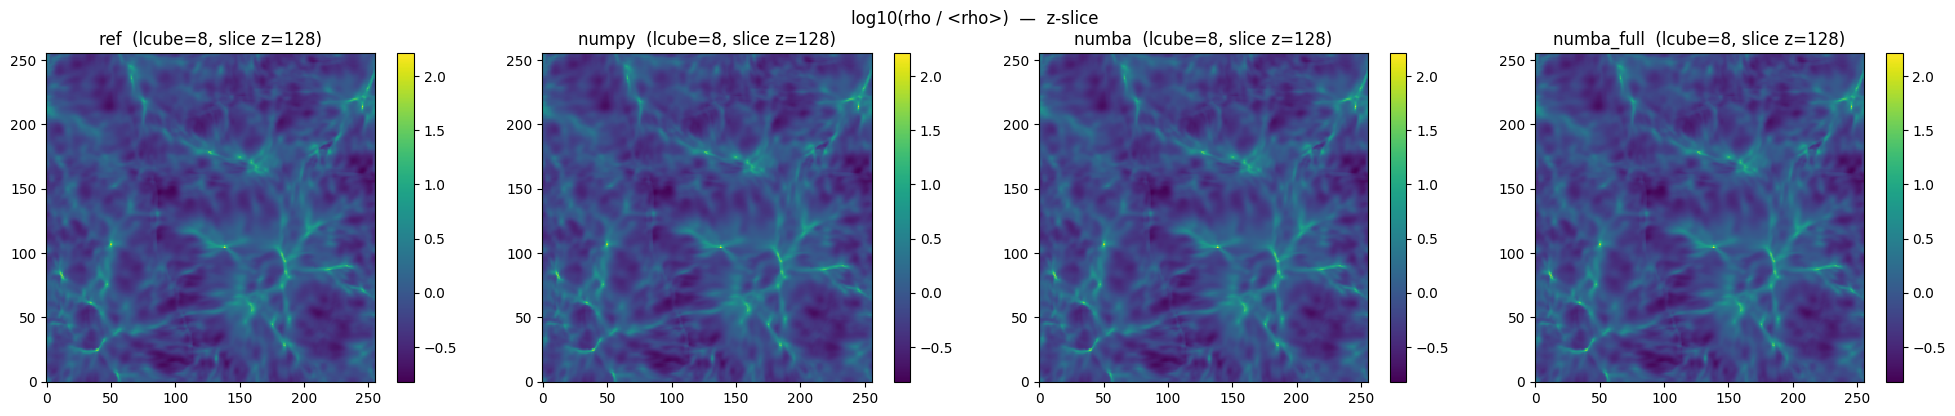

In [6]:
lcube_vis = LCUBES[0]
mid = 2**(lcube_vis - 1)  # middle slice index

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(5 * len(VARIANTS), 4))
for ax, name in zip(axes, VARIANTS):
    arr = results[(name, lcube_vis)]['result']
    avg = np.mean(arr[arr > 0])
    im = ax.imshow(np.log10(arr[:, :, mid] / avg + 1e-6).T,
                   origin='lower', interpolation='none')
    ax.set_title(f'{name}  (lcube={lcube_vis}, slice z={mid})')
    plt.colorbar(im, ax=ax)
plt.suptitle('log10(rho / <rho>)  —  z-slice')
plt.tight_layout()
plt.show()

## 6 — Difference map (numpy vs ref, numba vs ref)

numpy: max |diff| = 0.000e+00
numba: max |diff| = 0.000e+00
numba_full: max |diff| = 0.000e+00


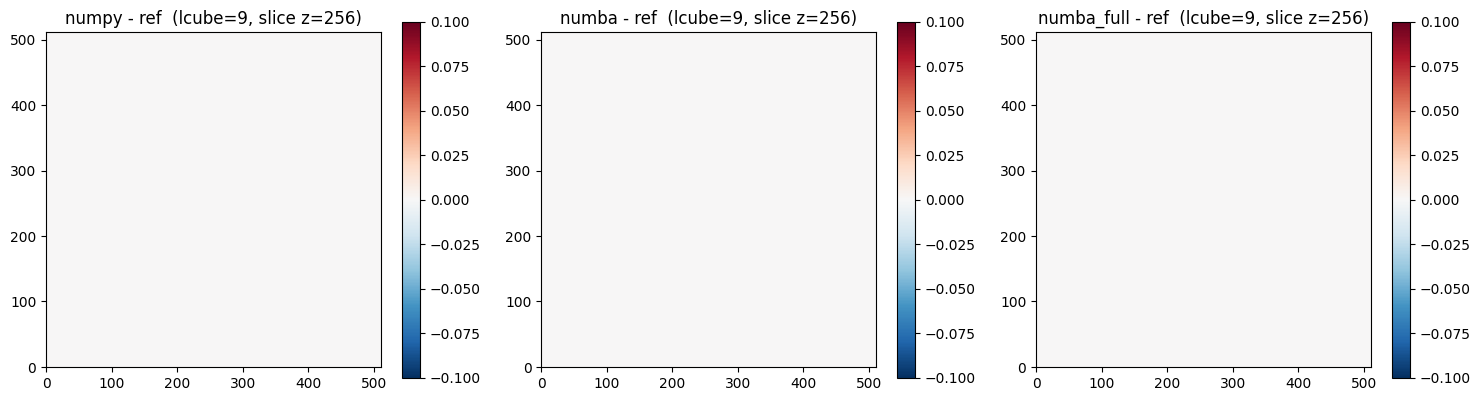

In [7]:
lcube_diff = LCUBES[-1]   # most interesting at highest lcube (more coarse cells)
mid = 2**(lcube_diff - 1)

ref_arr = results[('ref', lcube_diff)]['result']
compare_variants = [v for v in VARIANTS if v != 'ref']

fig, axes = plt.subplots(1, len(compare_variants),
                          figsize=(5 * len(compare_variants), 4))
if len(compare_variants) == 1:
    axes = [axes]

for ax, name in zip(axes, compare_variants):
    diff = results[(name, lcube_diff)]['result'] - ref_arr
    im = ax.imshow(diff[:, :, mid].T, origin='lower', interpolation='none',
                   cmap='RdBu_r')
    ax.set_title(f'{name} - ref  (lcube={lcube_diff}, slice z={mid})')
    plt.colorbar(im, ax=ax)
    print(f'{name}: max |diff| = {np.max(np.abs(diff)):.3e}')

plt.tight_layout()
plt.show()